In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gzip
import math


def calc_area_of_two_circle_intersection(x, r, X, R):
    d = abs(x-X)
    rad_sum = r+R
    rad_diff = r-R
    if (d >= rad_sum):
        return 0
    if (d <= abs(rad_diff)):
        if (rad_diff < 0):
            return math.pi*(r**2)
        return math.pi*(R**2)
    term1 = (r**2)*math.acos(((d**2)+(r**2)-(R**2))/(2*d*r))
    term2 = (R**2)*math.acos(((d**2)+(R**2)-(r**2))/(2*d*R))
    term3 = (1/2)*math.sqrt((-d+r+R)*(d+r-R)*(d-r+R)*(d+r+R))
    return term1+term2-term3

def calc_percentage_overlap(x, r, X, R):
    area_of_circle1 = math.pi*(r**2)
    area_of_circle2 = math.pi*(R**2)
    area_of_overlap = calc_area_of_two_circle_intersection(x, r, X, R)
    total_area = area_of_circle1 + area_of_circle2 - area_of_overlap
    return area_of_overlap / total_area

def position_circles(r, R, desired_overlap, iter=100, error=0.00001):
    bounds = [0, r+R]
    X = sum(bounds)/2
    estimated_overlap = -1
    counter = 0
    while abs(estimated_overlap - desired_overlap) > error:
        if counter >= iter:
            raise RuntimeError(f"Failed to find a solution for overlapping circles with radii {r} and {R} at ~{round(desired_overlap*100)}%.")
        estimated_overlap = calc_percentage_overlap(0, r, X, R)
        if estimated_overlap > desired_overlap:
            bounds = [X, bounds[1]]
            X = sum(bounds)/2
        elif estimated_overlap < desired_overlap:
            bounds = [bounds[0], X]
            X = sum(bounds)/2
    return 0, X

def draw_euler_diagram(a, A, overlap, save_to=False, c1=False, c2=False):
    if c1 is False:
        c1 = "black"
    if c2 is False:
        c2 = "black"
    
    r = math.sqrt(a/math.pi)
    R = math.sqrt(A/math.pi)

    x, X = position_circles(r, R, overlap)
    
    circle0 = plt.Circle((x,0), r, color=c1, fill=False, linewidth=2)
    circle1 = plt.Circle((X,0), R, color=c2, fill=False, linewidth=2)
    fig, ax = plt.subplots()
    ax.add_patch(circle0)
    ax.add_patch(circle1)
    
    y_bound = R
    if r > R:
        y_bound = r
        
    plt.xlim(x-r, X+R)
    plt.ylim(x-y_bound, x+y_bound)

    plt.axis("equal")
    plt.axis("off")

    if save_to is not False:
        plt.savefig(save_to)

    plt.show()

In [ ]:
responses = pd.read_csv("../data/student_activity_responses/student_activity_combined_responses.csv")

### Generate figures

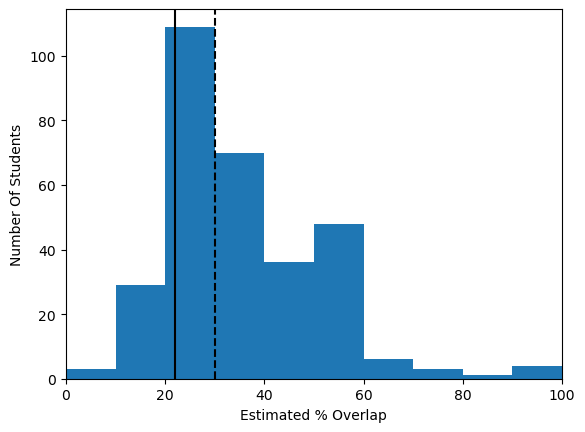

In [28]:
plt.hist(responses["interpretability_overlap0"], bins=range(0,110,10))
plt.axvline(responses["interpretability_overlap0"].median(), color="black", linestyle="dashed")
plt.axvline(22, color="black")
plt.xlim(0,100)
plt.xlabel("Estimated % Overlap")
plt.ylabel("Number Of Students")
plt.savefig("fig1/b/interpretability_overlap0.svg")
plt.show()

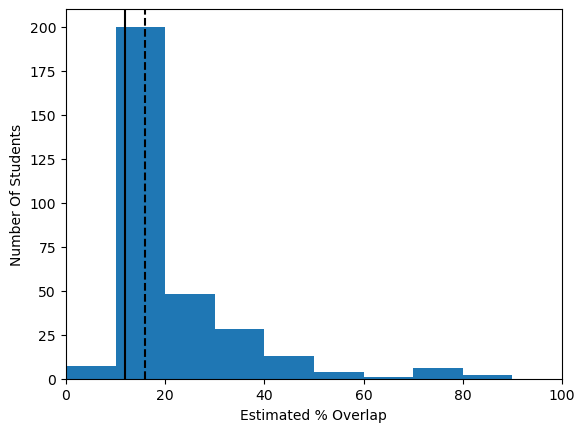

In [29]:
plt.hist(responses["interpretability_overlap1"], bins=range(0,110,10))
plt.axvline(responses["interpretability_overlap1"].median(), color="black", linestyle="dashed")
plt.axvline(12, color="black")
plt.xlim(0,100)
plt.xlabel("Estimated % Overlap")
plt.ylabel("Number Of Students")
plt.savefig("fig1/b/interpretability_overlap1.svg")
plt.show()

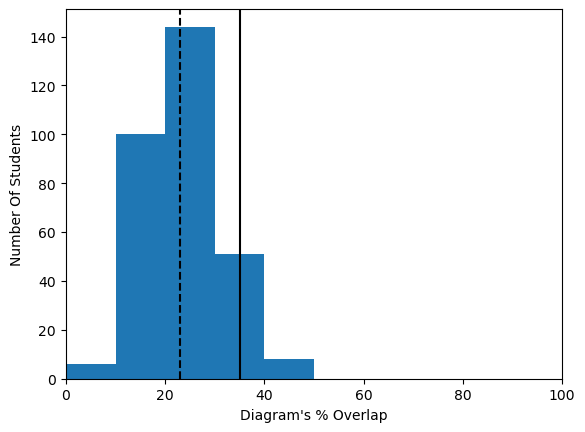

In [30]:
plt.hist(responses["build_your_own_overlap0"], bins=range(0,110,10))
plt.axvline(responses["build_your_own_overlap0"].median(), color="black", linestyle="dashed")
plt.axvline(35, color="black")
plt.xlim(0,100)
plt.xlabel("Diagram's % Overlap")
plt.ylabel("Number Of Students")
plt.savefig("fig1/c/build_your_own_overlap0.svg")
plt.show()

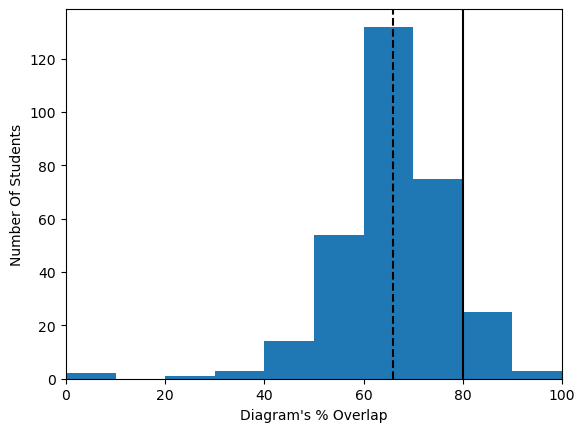

In [31]:
plt.hist(responses["build_your_own_overlap1"], bins=range(0,110,10))
plt.axvline(responses["build_your_own_overlap1"].median(), color="black", linestyle="dashed")
plt.axvline(80, color="black")
plt.xlim(0,100)
plt.xlabel("Diagram's % Overlap")
plt.ylabel("Number Of Students")
plt.savefig("fig1/c/build_your_own_overlap1.svg")
plt.show()

### ACB versus CEU

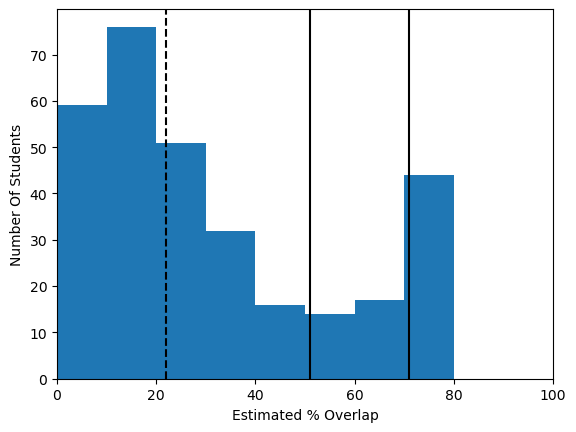

In [45]:
plt.hist(responses["thousand_genomes_overlap0"], bins=range(0,110,10))
plt.axvline(responses["thousand_genomes_overlap0"].median(), color="black", linestyle="dashed")
plt.axvline(51, color="black")
plt.axvline(71, color="black")
plt.xlim(0,100)
plt.xlabel("Estimated % Overlap")
plt.ylabel("Number Of Students")
plt.savefig("figS1/a/ACB_CEU_hist.svg")
plt.show()

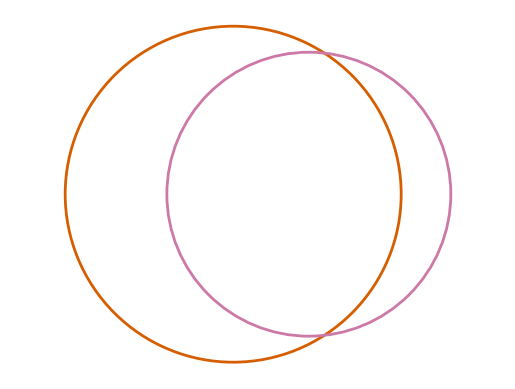

In [33]:
draw_euler_diagram(
    8018649,
    5726377,
    0.51,
    save_to="figS1/a/ACB_CEU_truth.svg",
    c1="#D55E00",
    c2="#cc79a7"
)

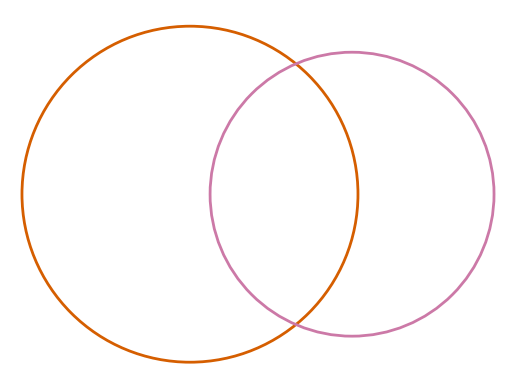

In [34]:
draw_euler_diagram(
    8018649,
    5726377,
    responses["thousand_genomes_overlap0"].median()/100,
    save_to="figS1/a/ACB_CEU_median.svg",
    c1="#D55E00",
    c2="#cc79a7"
)

### ACB versus MXL

30.0


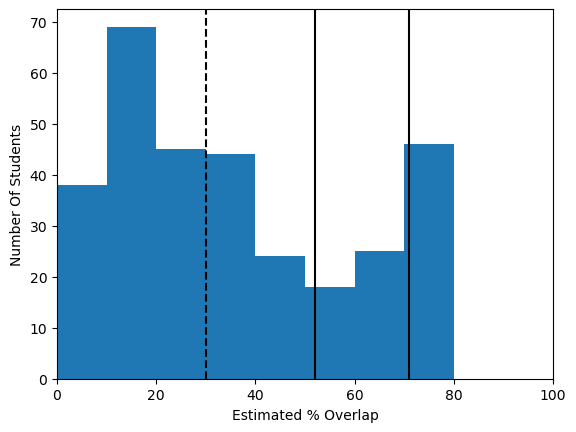

In [46]:
print(responses["thousand_genomes_overlap1"].median())
plt.hist(responses["thousand_genomes_overlap1"], bins=range(0,110,10))
plt.axvline(responses["thousand_genomes_overlap1"].median(), color="black", linestyle="dashed")
plt.axvline(52, color="black")
plt.axvline(71, color="black")
plt.xlim(0,100)
plt.xlabel("Estimated % Overlap")
plt.ylabel("Number Of Students")
plt.savefig("figS1/b/ACB_MXL_hist.svg")
plt.show()

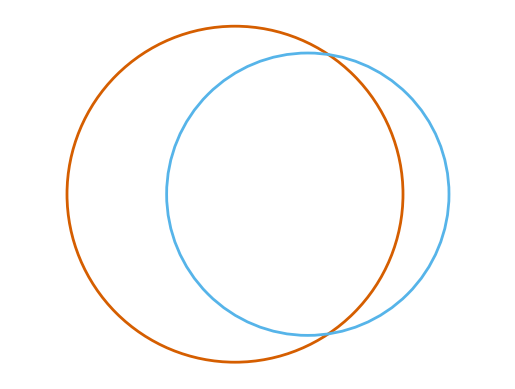

In [36]:
draw_euler_diagram(
    8018649,
    5663208,
    0.52,
    save_to="figS1/b/ACB_MXL_truth.svg",
    c1="#D55E00",
    c2="#56b4e9"
)

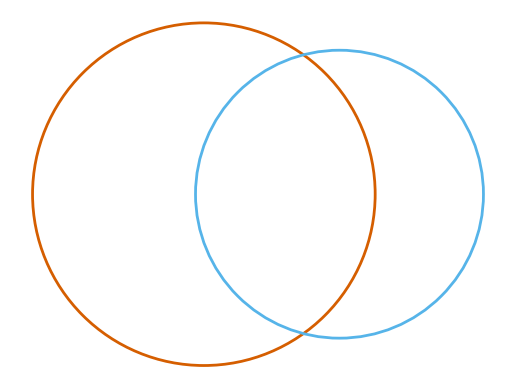

In [37]:
draw_euler_diagram(
    8018649,
    5663208,
    responses["thousand_genomes_overlap1"].median()/100,
    save_to="figS1/b/ACB_MXL_median.svg",
    c1="#D55E00",
    c2="#56b4e9"
)

### CEU versus MXL

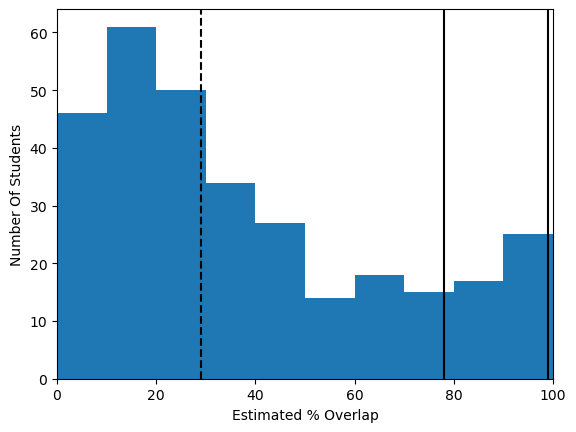

In [47]:
plt.hist(responses["thousand_genomes_overlap2"], bins=range(0,110,10))
plt.axvline(responses["thousand_genomes_overlap2"].median(), color="black", linestyle="dashed")
plt.axvline(78, color="black")
plt.axvline(99, color="black")
plt.xlim(0,100)
plt.xlabel("Estimated % Overlap")
plt.ylabel("Number Of Students")
plt.savefig("figS1/c/CEU_MXL_hist.svg")
plt.show()

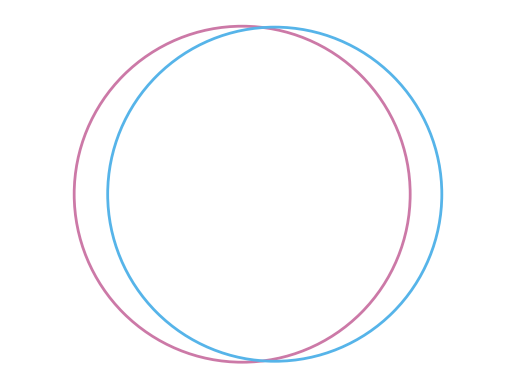

In [39]:
draw_euler_diagram(
    5726377,
    5663208,
    0.78,
    save_to="figS1/c/CEU_MXL_truth.svg",
    c1="#cc79a7",
    c2="#56b4e9"
)

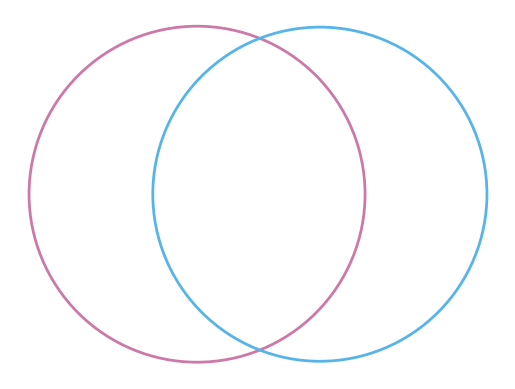

In [40]:
draw_euler_diagram(
    5726377,
    5663208,
    responses["thousand_genomes_overlap2"].mean()/100,
    save_to="figS1/c/CEU_MXL_median.svg",
    c1="#cc79a7",
    c2="#56b4e9"
)

### Student Responses Analysis

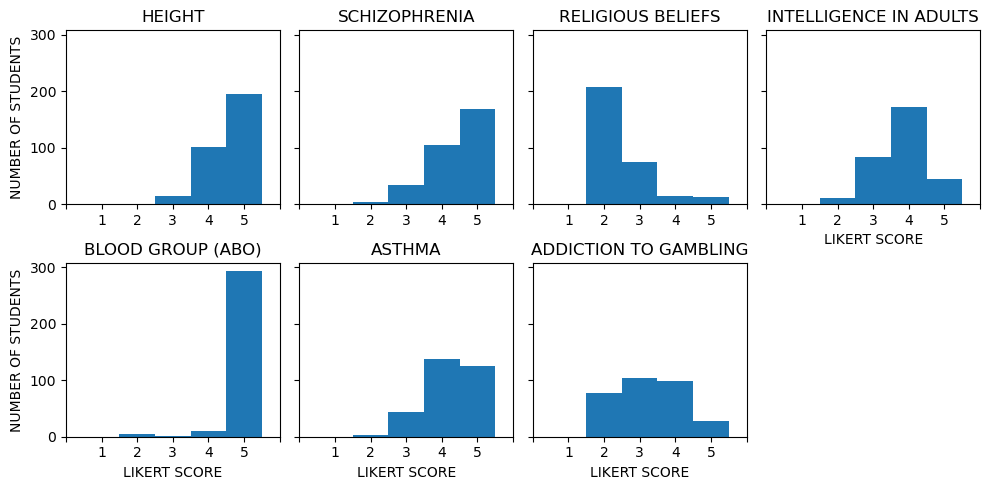

In [140]:
labels = list(range(0, 7))
labels[0] = ""
labels[-1] = ""

fig, (ax1, ax2) = plt.subplots(2, 4, figsize=(10, 5), sharey=True)
ax1[0].hist(responses["genetics_background_likert1"], bins=range(0,6))
ax1[0].set_xticks([t/10 for t in range(-5, 65, 10)], labels=labels)
ax1[0].set_ylabel("NUMBER OF STUDENTS")
ax1[0].set_title("HEIGHT")
ax1[1].hist(responses["genetics_background_likert2"], bins=range(0,6))
ax1[1].set_xticks([t/10 for t in range(-5, 65, 10)], labels=labels)
ax1[1].set_title("SCHIZOPHRENIA")
ax1[2].hist(responses["genetics_background_likert3"], bins=range(0,6))
ax1[2].set_xticks([t/10 for t in range(-5, 65, 10)], labels=labels)
ax1[2].set_title("RELIGIOUS BELIEFS")
ax1[3].hist(responses["genetics_background_likert4"], bins=range(0,6))
ax1[3].set_xticks([t/10 for t in range(-5, 65, 10)], labels=labels)
ax1[3].set_xlabel("LIKERT SCORE")
ax1[3].set_title("INTELLIGENCE IN ADULTS")
ax2[0].hist(responses["genetics_background_likert5"], bins=range(0,6))
ax2[0].set_xticks([t/10 for t in range(-5, 65, 10)], labels=labels)
ax2[0].set_xlabel("LIKERT SCORE")
ax2[0].set_ylabel("NUMBER OF STUDENTS")
ax2[0].set_title("BLOOD GROUP (ABO)")
ax2[1].hist(responses["genetics_background_likert6"], bins=range(0,6))
ax2[1].set_xticks([t/10 for t in range(-5, 65, 10)], labels=labels)
ax2[1].set_xlabel("LIKERT SCORE")
ax2[1].set_title("ASTHMA")
ax2[2].hist(responses["genetics_background_likert7"], bins=range(0,6))
ax2[2].set_xticks([t/10 for t in range(-5, 65, 10)], labels=labels)
ax2[2].set_xlabel("LIKERT SCORE")
ax2[2].set_title("ADDICTION TO GAMBLING")
ax2[3].axis("off")
plt.tight_layout()
plt.savefig("figS2/a/likert_responses.svg")
plt.show()

In [141]:
responses["interpretability_overlap0_error"] = 22 - responses["interpretability_overlap0"]
responses["interpretability_overlap1_error"] = 12 - responses["interpretability_overlap1"]
responses["build_your_own_overlap0_error"] = 35 - responses["build_your_own_overlap0"]
responses["build_your_own_overlap1_error"] = 80 - responses["build_your_own_overlap1"]
responses["thousand_genomes_overlap0_error"] = 51 - responses["thousand_genomes_overlap0"]
responses["thousand_genomes_overlap1_error"] = 52 - responses["thousand_genomes_overlap1"]
responses["thousand_genomes_overlap2_error"] = 78 - responses["thousand_genomes_overlap2"]

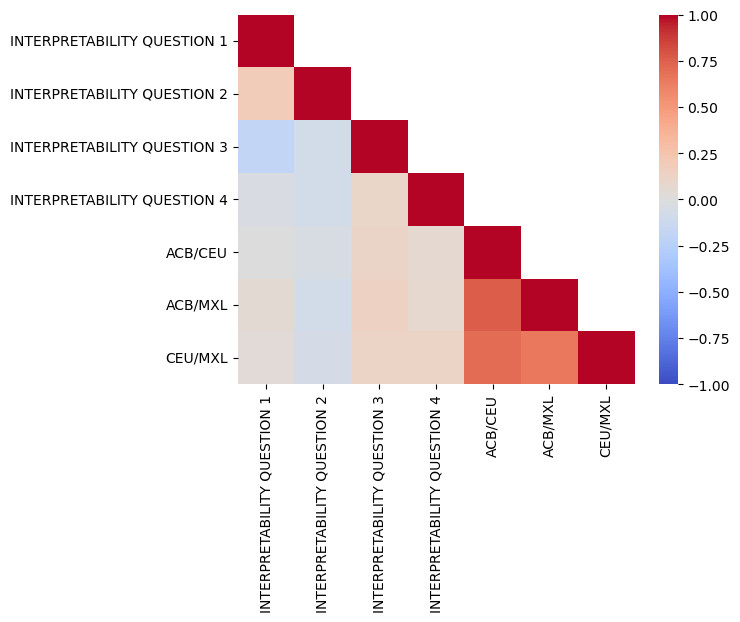

In [145]:
error = responses[[
    "interpretability_overlap0_error",
    "interpretability_overlap1_error",
    "build_your_own_overlap0_error",
    "build_your_own_overlap1_error",
    "thousand_genomes_overlap0_error",
    "thousand_genomes_overlap1_error",
    "thousand_genomes_overlap2_error"
]]

# Compute correlation matrix
co_mtx = error.corr(numeric_only=True)

upper_mask = np.triu(np.ones_like(co_mtx, dtype=bool), k=1)

column_labels = [
    "INTERPRETABILITY QUESTION 1",
    "INTERPRETABILITY QUESTION 2",
    "INTERPRETABILITY QUESTION 3",
    "INTERPRETABILITY QUESTION 4",
    "ACB/CEU",
    "ACB/MXL",
    "CEU/MXL"
]

# Plot correlation heatmap
sns.heatmap(
    co_mtx,
    mask=upper_mask,
    xticklabels=column_labels,
    yticklabels=column_labels,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

plt.savefig("figS2/b/correlation_in_error.svg")

# Display heatmap
plt.show()

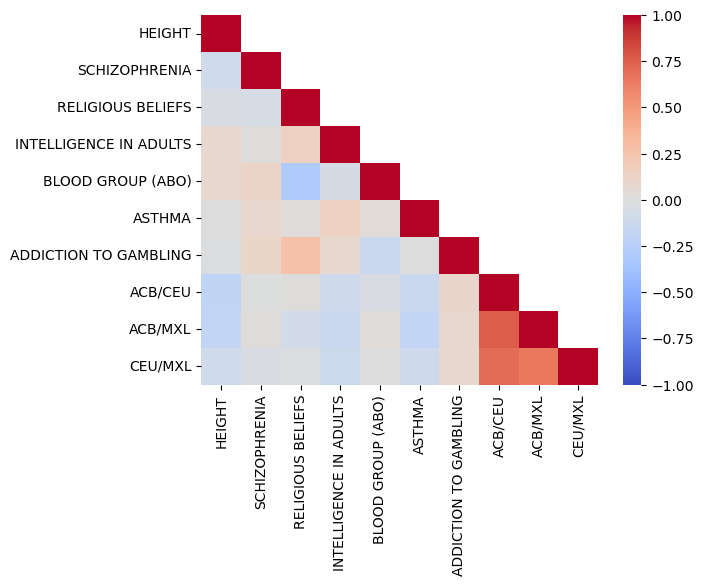

In [144]:
likert = responses[[
    "genetics_background_likert1",
    "genetics_background_likert2",
    "genetics_background_likert3",
    "genetics_background_likert4",
    "genetics_background_likert5",
    "genetics_background_likert6",
    "genetics_background_likert7",
    "thousand_genomes_overlap0",
    "thousand_genomes_overlap1",
    "thousand_genomes_overlap2"
]]

# Compute correlation matrix
co_mtx = likert.corr(numeric_only=True)

upper_mask = np.triu(np.ones_like(co_mtx, dtype=bool), k=1)

column_labels = [
    "HEIGHT",
    "SCHIZOPHRENIA",
    "RELIGIOUS BELIEFS",
    "INTELLIGENCE IN ADULTS",
    "BLOOD GROUP (ABO)",
    "ASTHMA",
    "ADDICTION TO GAMBLING",
    "ACB/CEU",
    "ACB/MXL",
    "CEU/MXL"
]

# Plot correlation heatmap
sns.heatmap(
    co_mtx,
    mask=upper_mask,
    xticklabels=column_labels,
    yticklabels=column_labels,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

plt.savefig("figS2/c/correlation_in_likert.svg")

# Display heatmap
plt.show()